# Probar clasificadores preentrenados
**MobileNet/AffectNet (TensorFlow/Keras) y Residual Masking Network int8 (ONNX Runtime CPU).**
Usa el kernel `.venv` del proyecto. No se entrenan redes ni se alteran los modelos anteriores.

**Importante:** la validación del proyecto sale del entrenamiento de FER2013. RMN fue entrenado
con FER2013 y puede haber visto estas imágenes. Los resultados aquí son **exploratorios**,
no una medición independiente ni una reproducción del benchmark de los artículos.
La versión RMN int8 tampoco tiene garantizado el 74,14 % publicado para el modelo del benchmark.

Los modelos tienen siete salidas. Miedo se conserva: una predicción de miedo para una imagen
de nuestras seis categorías cuenta como error; no se fuerza otra categoría.
No se usa la carpeta test. La última sección permite evaluar fotos nuevas etiquetadas.

Fuentes: [MobileNet](https://github.com/sb-ai-lab/EmotiEffLib),
[pesos RMN](https://huggingface.co/phamquiluan/ResidualMaskingNetwork).

In [1]:
from pathlib import Path, PureWindowsPath
from datetime import datetime
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from preentrenados_runtime import Clasificadores, CLASES, SALIDAS, registrar_pesos

BASE = Path.cwd()
if not (BASE / 'train').is_dir():
    raise FileNotFoundError('Abre la carpeta Neuro-IA-Marketing en VS Code.')
print('Proyecto:', BASE)
print('Seis clases del proyecto:', CLASES)

Proyecto: C:\Users\Garcia\Desktop\Neuro-IA-Marketing
Seis clases del proyecto: ['angry', 'disgusted', 'happy', 'neutral', 'sad', 'surprised']


## 1. Cargar modelos
Los pesos ya están descargados en `modelos/preentrenados`. RMN usa ONNX Runtime; no necesitas aprender PyTorch para esta prueba. MobileNet usa su preprocesamiento oficial, diferente de dividir por 255.

In [2]:
clasificadores = Clasificadores(BASE)
registrar_pesos(BASE)
print('MobileNet:', clasificadores.mobile.input_shape, clasificadores.mobile.output_shape)
print('RMN:', clasificadores.rmn.get_inputs()[0].shape)
print('Orden común de salidas:', SALIDAS)

MobileNet: (None, 224, 224, 3) (None, 7)
RMN: [1, 3, 224, 224]
Orden común de salidas: ['angry', 'disgusted', 'fearful', 'happy', 'neutral', 'sad', 'surprised']


## 2. Recuperar exactamente la misma validación
Se utiliza el archivo de división guardado durante V2. No se vuelve a dividir el dataset.

In [3]:
division = np.load(BASE / 'modelos' / 'CNN_V2_20261013_192239_735567' / 'division_datos.npz', allow_pickle=False)
# Reconstruir rutas para que también sirvan al abrir la misma carpeta desde WSL.
rutas_val = [BASE / 'train' / PureWindowsPath(str(p)).parts[-2] / PureWindowsPath(str(p)).name
             for p in division['x_val']]
reales_val = [CLASES[int(i)] for i in division['y_val']]
if not rutas_val or not all(p.is_file() for p in rutas_val):
    raise FileNotFoundError('Faltan imágenes de la división original.')
print('Imágenes de validación exploratoria:', len(rutas_val))

Imágenes de validación exploratoria: 1527


## 3. Ejecutar la comparación exploratoria
Procesa toda la validación. Se informa exactitud, F1 promedio de las seis categorías,
predicciones de miedo y mediana de milisegundos por rostro.
La latencia incluye redimensionado, preprocesamiento e inferencia; excluye lectura del disco,
captura, detección facial, red y arranque del modelo. No equivale a los FPS del sistema completo.
Las fotos de FER son pequeñas y grises; ampliarlas a 224×224 no recupera detalles ni color.
No compares estos porcentajes como si fueran una evaluación independiente frente a la CNN propia.

MobileNet: 100/1527
MobileNet: 200/1527
MobileNet: 300/1527
MobileNet: 400/1527
MobileNet: 500/1527
MobileNet: 600/1527
MobileNet: 700/1527
MobileNet: 800/1527
MobileNet: 900/1527
MobileNet: 1000/1527
MobileNet: 1100/1527
MobileNet: 1200/1527
MobileNet: 1300/1527
MobileNet: 1400/1527
MobileNet: 1500/1527
{"modelo": "MobileNet", "accuracy": 0.4905042567125082, "macro_f1_6_clases": 0.5388499244110391, "predicciones_miedo": 273, "imagenes": 1527, "mediana_ms_por_rostro": 67.96719995327294, "contexto": "FER/RAF exploratoria; posible solapamiento"}
              precision    recall  f1-score   support

       angry      0.421     0.395     0.408       263
   disgusted      0.685     0.464     0.553       263
       happy      0.813     0.732     0.771       250
     neutral      0.538     0.448     0.489       250
         sad      0.522     0.526     0.524       251
   surprised      0.671     0.384     0.489       250

   micro avg      0.597     0.491     0.539      1527
   macro avg    

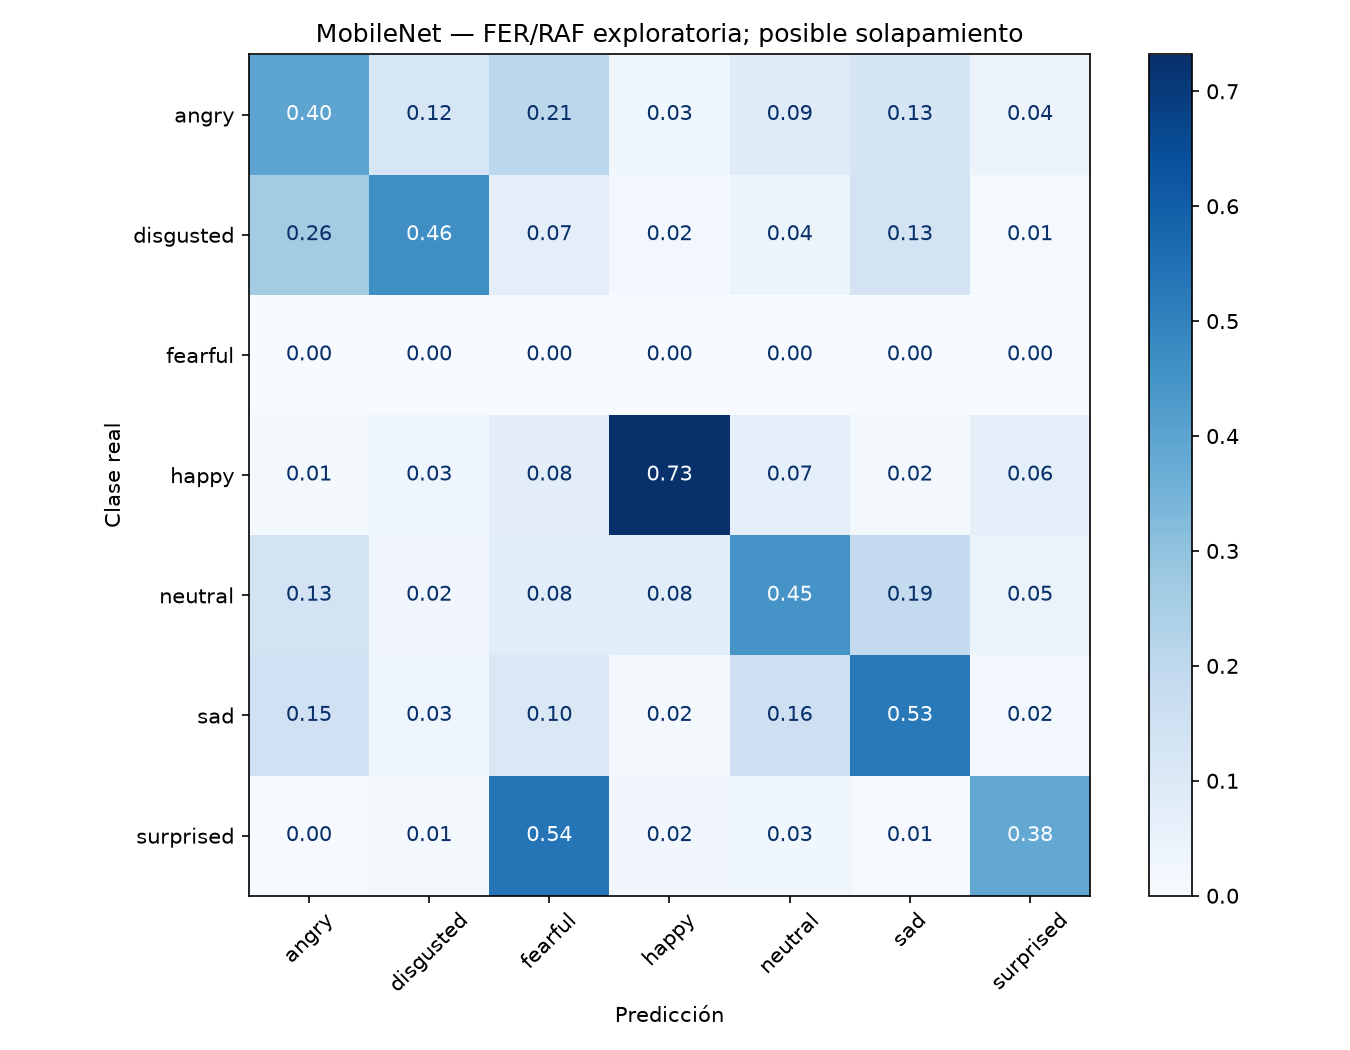

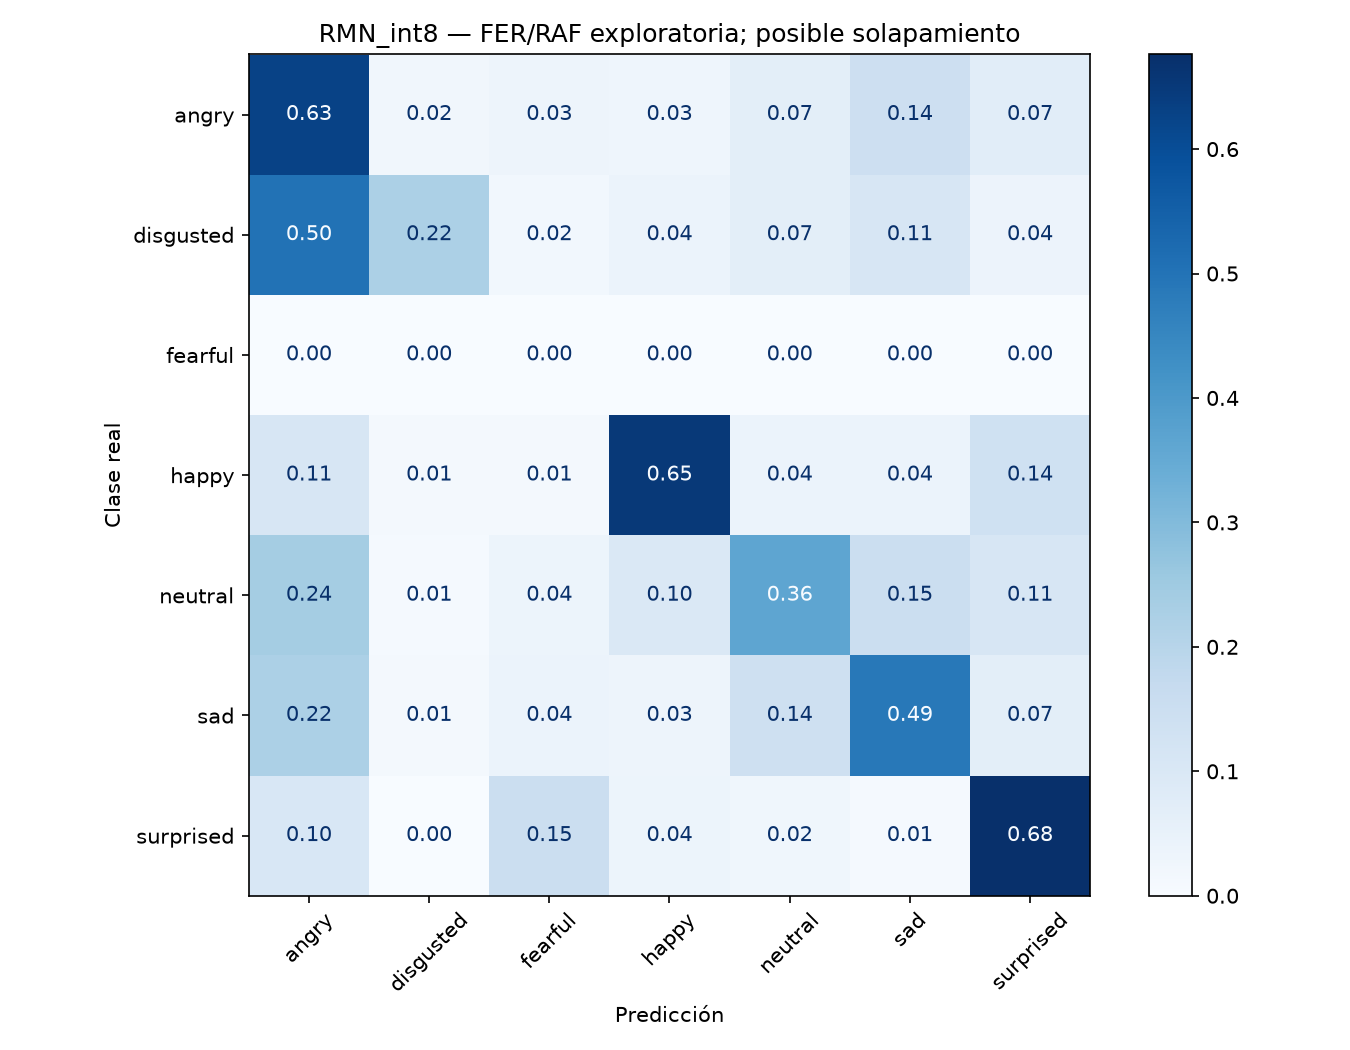

In [4]:
SALIDA = BASE / 'resultados_preentrenados' / datetime.now().strftime('Exploratoria_%Y%m%d_%H%M%S_%f')
resultados = clasificadores.evaluar(rutas_val, reales_val, SALIDA,
    contexto='FER/RAF exploratoria; posible solapamiento')
print('Resultados guardados:', SALIDA)

## 4. Probar una foto nueva de un rostro recortado
Configura `FOTO` con la ruta a una cara ya recortada. Esta sección no detecta rostros:
no utilices una foto completa con varias personas. No se suben imágenes a servidores.
Una predicción aislada permite comprobar funcionamiento, pero no medir exactitud.

In [ ]:
FOTO = None  # Ejemplo: BASE / 'mi_rostro.jpg'
if FOTO is None:
    print('Configura FOTO con la ruta de un rostro recortado para probarlo.')
else:
    with Image.open(FOTO) as rostro:
        plt.imshow(rostro)
        plt.axis('off')
        plt.show()
        for nombre in ('MobileNet', 'RMN_int8'):
            scores = clasificadores.predecir(rostro, nombre)
            print(nombre, '->', SALIDAS[int(np.argmax(scores))])
            print(dict(zip(SALIDAS, np.round(scores, 3))))

## 5. Evaluación independiente con rostros nuevos
Guarda rostros nuevos, recortados y etiquetados, en `evaluacion_nueva/angry`, `disgusted`,
`happy`, `neutral`, `sad` y `surprised`. Usa varias personas y condiciones parecidas a la cámara del
proyecto. No copies imágenes de FER/RAF aquí. Las etiquetas describen expresiones observables.
Estas imágenes no deben participar en ajustes o entrenamiento si se van a usar como evaluación final.
Es necesario tener ejemplos en las seis categorías para realizar esta comparación.

In [ ]:
rutas_nuevas, reales_nuevas, faltantes = [], [], []
for clase in CLASES:
    carpeta = BASE / 'evaluacion_nueva' / clase
    archivos = sorted(p for p in carpeta.iterdir() if p.is_file()
        and p.suffix.lower() in ('.jpg', '.jpeg', '.png')) if carpeta.is_dir() else []
    if not archivos:
        faltantes.append(clase)
    rutas_nuevas.extend(archivos)
    reales_nuevas.extend([clase] * len(archivos))
if faltantes:
    print('Aún faltan fotos nuevas en:', ', '.join(faltantes))
else:
    SALIDA_NUEVA = BASE / 'resultados_preentrenados' / datetime.now().strftime('Independiente_%Y%m%d_%H%M%S_%f')
    resultados_nuevos = clasificadores.evaluar(rutas_nuevas, reales_nuevas, SALIDA_NUEVA,
        contexto='Rostros nuevos; evaluación independiente')
    print('Resultados independientes:', SALIDA_NUEVA)